### PHYS 4730 Lab 21 Exercise: Gini Impurity 

Please follow the steps given in the markdown cells below to complete this lab.

     - JB 20261110

In [1]:
%reset -f

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams.update({'font.size': 18})

/home/belz/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
### generate the two datasets we'd like to separate ###

np.random.seed(16) # this insures that our random numbers will be the same each time      

xmin = -10.0
xmax =  10.0
ymin = -10.0
ymax =  10.0

MU1X, MU1Y =   2.0,  0.5
SG1X, SG1Y =   3.0,  2.0 
N1         =   140

MU2X, MU2Y =  -1.5, -3.5
SG2X, SG2Y =   2.0,  2.0 
N2         =   100

RV1X = np.random.normal(MU1X,   SG1X, N1)
RV1Y = np.random.normal(MU1Y,   SG1Y, N1)
RV2X = np.random.normal(MU2X,   SG2X, N2)
RV2Y = np.random.normal(MU2Y,   SG2Y, N2)

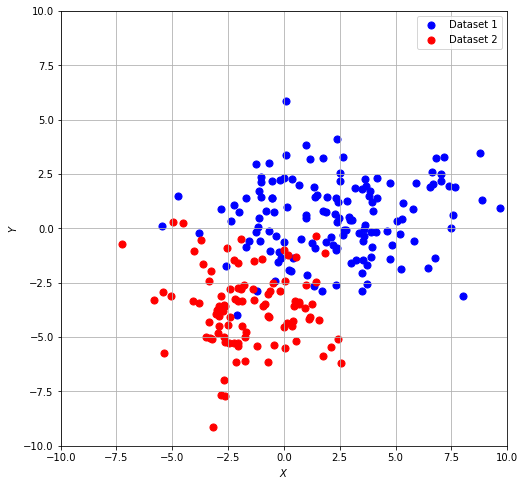

In [3]:
### plot the 'data' ###

plt.figure(figsize=(8,8))
plt.scatter(RV1X,RV1Y, c = 'blue', s=50, label="Dataset 1")
plt.scatter(RV2X,RV2Y, c = 'red',  s=50, label="Dataset 2")
plt.xlabel('$X$')
plt.ylabel('$Y$')
plt.axis([xmin,xmax,ymin,ymax])
plt.grid()
plt.legend()
plt.show()

1) Create a function <b>choose_cut</b> to randomly pick a horizontal cut to separate the data 

In [4]:
def choose_cut(yhmin,yhmax):
    
    # randomly pick a horizontal cut between yhmin and yhmax
    
    yline = np.random.uniform(yhmin,yhmax,1)[0]
    
    return yline    

2) Create a function <b>gini2</b> to compute Gini Impurity for two classes of data. The function should take as input the number of each class that are present in a particular region of <i>(X,Y)</i> space.

In [5]:
def gini2(n1,n2):
    
    # compute gini impurity for two classes of data 
    
    ntot = n1 + n2
    g2   = 1.0 - (n1/ntot)**2 - (n2/ntot)**2
    
    return g2

3) Use <b>gini2</b> to compute the Gini Impurity of the full data. Output the result.

In [6]:
gini_orig = gini2(len(RV1Y),len(RV2Y))
print("the data initially has Gini Impurity of %5.3f" % gini_orig)

the data initially has Gini Impurity of 0.486


4) Create a function <b>divdata</b> which takes as input two 1D arrays of the <i>Y</i>-variable and the horizontal cut, and outputs four integers:
<ul>
    <li> the number of elements of array 1 which are &ldquo;above&rdquo; the cutoff
    <li> the number of elements of array 1 which are &ldquo;below&rdquo; the cutoff
    <li> the number of elements of array 2 which are &ldquo;above&rdquo; the cutoff
    <li> the number of elements of array 2 which are &ldquo;below&rdquo; the cutoff
</ul>    

In [7]:
def divdata(array1,array2,yline):
    
    array1_div = np.array([])
    array2_div = np.array([])
    
    n1above = 0
    n1below = 0 
    n2above = 0
    n2below = 0 
    
    for i in np.arange(0,len(array1)):
        
        if(array1[i] > yline):
            n1above += 1
        else:
            n1below += 1
            
    for i in np.arange(0,len(array2)):

        if(array2[i] > yline):
            n2above += 1
        else:
            n2below += 1
           
    return n1above,n1below,n2above,n2below

5) Now your main code. Following the pseudocode below, perform the following:

    * Choose a number of horizontal cuts to try 
    * For each of these trials
        * call <b>choose_cut</b> to randomly pick a cut
        * call <b>divdata</b> to count number of elements of dataset (1/2) (above/below) the cut
        * call <b>gini2</b> to compute Gini Impurity above and below the cut
        * compute the change in Gini Impurity $\Delta G$ relative to the Gini Impurity of the full data
        * save the cut values and $\Delta G$ in 1D arrays 

123 17 17 83


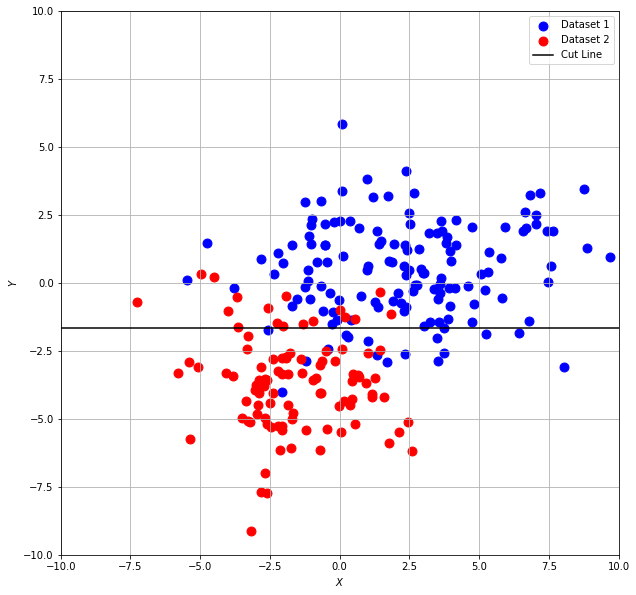

In [8]:
nlines = 100

ycut = np.array([])
gini = np.array([])
dg   = np.array([])

for i in np.arange(0,nlines):
    
    n1 = len(RV1Y)
    n2 = len(RV2Y)
    
    ycut = np.append(ycut,choose_cut(-7.5,2.5))
    n1a,n1b,n2a,n2b = divdata(RV1Y,RV2Y,ycut[i])
    
    if(i==0 and True):
        
        print(n1a,n1b,n2a,n2b)
        
        plt.figure(figsize=(10,10))
        plt.scatter(RV1X,RV1Y, c = 'blue', s=80, label="Dataset 1")
        plt.scatter(RV2X,RV2Y, c = 'red',  s=80, label="Dataset 2")
        plt.plot([xmin,xmax],[ycut[i],ycut[i]], c = 'black', label="Cut Line")
        plt.xlabel('$X$')
        plt.ylabel('$Y$')
        plt.axis([xmin,xmax,ymin,ymax])
        plt.grid()
        plt.legend()
        plt.show()
        
    gini_above = gini2(n1a,n2a)
    gini_below = gini2(n1b,n2b)
    
    dgini = gini_orig - (gini_above*(n1a+n2a)/(n1+n2)) - (gini_below*(n1b+n2b)/(n1+n2))
    
    dg = np.append(dg,dgini)
        

6) Plot the decrease in Gini Impurity $\Delta G$ versus the cut value. It may be desirable to use a logarithmic vertical axis on this plot. 

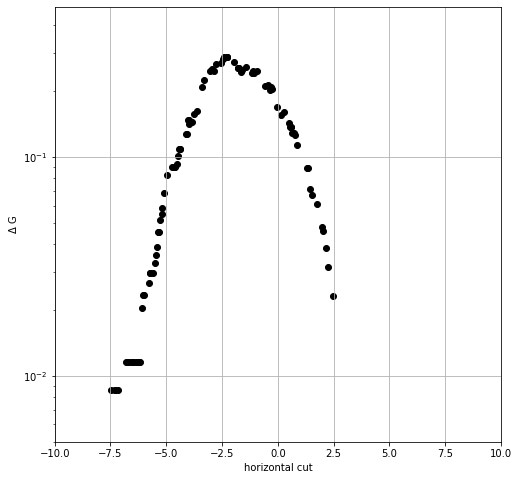

In [9]:
### plot the decrease in impurity vs ycut ###

plt.figure(figsize=(8,8))
plt.scatter(ycut,dg,c="black")
plt.xlabel('horizontal cut')
plt.ylabel('$\Delta$ G')
plt.yscale("log")
plt.axis([ymin,ymax,0.005,gini_orig])
plt.grid()
plt.show()

7) Output the $Y$-cut value which produces the maximum decrease in impurity.

In [10]:
ybest = ycut[np.argmax(dg)]
print("the maximum decrease in impurity occurs at Y = %5.2f" % ybest)

the maximum decrease in impurity occurs at Y = -2.43


8) Finally, replot the data with the &ldquo;best&rdquo; horizontal cut superimposed.

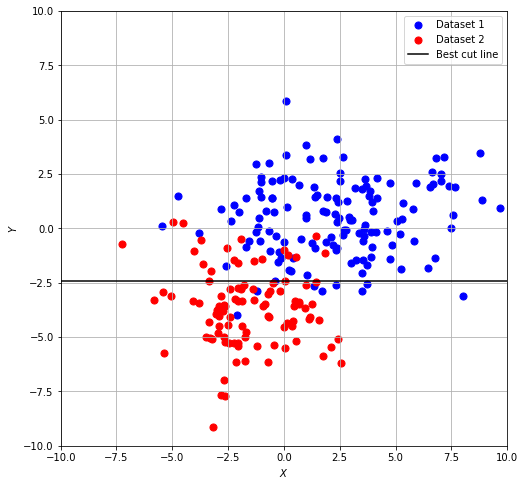

In [11]:
### plot the 'data' with best horizontal cut superimposed ###

plt.figure(figsize=(8,8))
plt.scatter(RV1X,RV1Y, c = 'blue', s=50, label="Dataset 1")
plt.scatter(RV2X,RV2Y, c = 'red',  s=50, label="Dataset 2")
plt.plot([xmin,xmax],[ybest,ybest], c = 'black', label="Best cut line")
plt.xlabel('$X$')
plt.ylabel('$Y$')
plt.axis([xmin,xmax,ymin,ymax])
plt.grid()
plt.legend()
plt.show()